# ****NEXT LEVEL MODELING****

Notebook ini menulis dan menguji Algoritma Genetika yang mencari batas interval terbaik bagi Fuzzy Time Series, lalu membandingkannya dengan pembagian interval lain pada jumlah interval yang sama.

<p align="center">
    <img src="../xLain_Lain/img/nlm_o.png" alt="Next Level Modeling" witdh="100" height="500">
</p>

---

### ****DAFTAR ISI****

0. Persiapan Lingkungan Kerja dan Pemuatan Data
1. Rancangan Algoritma Genetika
2. Pengujian Modul Algoritma Genetika
3. Satu Kali Jalan pada K = 15 dan Pembanding
4. Eksperimen Berulang pada Berbagai Jumlah Interval
5. Perbandingan dengan Model Dasar
6. Ringkasan dan Langkah Berikutnya

### ****0. Persiapan Lingkungan Kerja dan Pemuatan Data****

#### ****0.1 Mengapa langkah ini penting?****

Seperti pada Notebook 4, notebook ini hanya memuat data latih dan data validasi. Data uji tetap tidak disentuh sampai seluruh konfigurasi model terkunci. Hasil model dasar dari Notebook 4 juga dimuat agar hasil Algoritma Genetika dapat langsung dibandingkan dengan tolok ukur yang sama.

#### ****0.2 Memuat data dan hasil model dasar****

Sel berikut memuat paket dan modul proyek, data latih dan validasi, serta tabel hasil model dasar dari folder Model.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import config
from src.metrics import ringkas_metrik
from src.fts import interval_sama_panjang, FuzzyTimeSeriesChen
from src.ga import (mape_fts, lebar_ke_batas, perbaiki, jalankan_ga,
                    batas_kuantil, pencarian_acak)

rupiah = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))

pembagian = pd.read_csv(config.DIR_CLEAN / "pembagian_data.csv", parse_dates=["tanggal"])
pembagian = pembagian[pembagian["subset"].isin(["latih", "validasi"])]
latih = pembagian[pembagian["subset"] == "latih"].set_index("tanggal")["harga"]
validasi = pembagian[pembagian["subset"] == "validasi"].set_index("tanggal")["harga"]
semua = pd.concat([latih, validasi])
acuan_validasi = semua.shift(1).loc[validasi.index]

with open(config.DIR_MODEL / "konfigurasi_baseline.json", encoding="utf-8") as f:
    konfigurasi_baseline = json.load(f)
hasil_baseline = pd.read_csv(config.DIR_MODEL / "hasil_baseline_validasi.csv", index_col=0)

print("=" * 62)
print("Data dan hasil model yang dimuat")
print("=" * 62)
print(f"Data latih : {len(latih)} hari ({latih.index.min().date()} sampai {latih.index.max().date()})")
print(f"Data validasi : {len(validasi)} hari ({validasi.index.min().date()} sampai {validasi.index.max().date()})")
print("Data uji : sengaja tidak dimuat pada notebook ini")
print()
print("MAPE validasi model dasar dari Notebook 4:")
print(hasil_baseline["MAPE_%"].round(2).to_string())

Data dan hasil model yang dimuat
Data latih : 1221 hari (2020-01-02 sampai 2024-11-06)
Data validasi : 261 hari (2024-11-07 sampai 2025-11-06)
Data uji : sengaja tidak dimuat pada notebook ini

MAPE validasi model dasar dari Notebook 4:
ARIMA(3, 1, 2)                                3.67
Regresi linear (lag=7)                        3.76
Naive                                         3.85
FTS interval sama panjang (K=150, rujukan)    4.72
Perceptron berlapis (lag=5, 16 neuron)        4.97
Moving average (k=2)                          5.22
FTS interval sama panjang (K=15)              8.51


>INTERPRETASI (Pemuatan data dan hasil model dasar)
>
>Data latih (1.221 hari) dan data validasi (261 hari) termuat sesuai pembagian pada Notebook 3, dan data uji sengaja tidak dimuat. Tabel hasil model dasar dari Notebook 4 berhasil dibaca: naive 3,85%, ARIMA(3,1,2) 3,67%, dan Fuzzy Time Series interval sama panjang 8,51% pada K = 15. Angka-angka ini menjadi tolok ukur untuk hasil Algoritma Genetika.

### ****1. Rancangan Algoritma Genetika****

#### ****1.1 Mengapa langkah ini penting?****

Hasil Algoritma Genetika sangat dipengaruhi pilihan rancangan, mulai dari bentuk kromosom sampai parameter evolusi. Bila parameter disetel berulang kali sambil melihat hasil validasi, angka validasi menjadi terlalu optimistis. Karena itu seluruh rancangan di bawah ditetapkan sebelum eksperimen dijalankan dan tidak diubah mengikuti hasil.

#### ****1.2 Masalah optimasi****

Untuk jumlah interval K yang diberikan, dicari K dikurangi satu batas interior di antara harga terendah dan tertinggi data latih sehingga MAPE Fuzzy Time Series sekecil mungkin. Fungsi tujuannya bersifat patah-patah: menggeser sebuah batas sedikit kadang tidak mengubah apa pun, lalu tiba-tiba memindahkan beberapa data ke himpunan lain dan mengubah aturan. Fungsi seperti ini tidak mulus dan tidak dapat diturunkan, sehingga metode berbasis gradien tidak cocok dan pencarian berbasis populasi seperti Algoritma Genetika layak dicoba.

#### ****1.3 Rancangan****

1. Kromosom: K proporsi lebar interval yang berjumlah satu. Ujung semesta tetap (harga latih terendah dan tertinggi) dan batas diperoleh dari penjumlahan kumulatif lebar, sehingga batas selalu terurut dan menutup seluruh semesta.
2. Batasan: setiap interval minimal selebar 25% dari lebar pembagian sama panjang, agar interval tidak menyusut menjadi sempit sekali.
3. Fitness: MAPE pada data latih, yang diminimalkan. Metrik ini sama dengan metrik evaluasi.
4. Populasi awal: 60 individu, terdiri atas satu pembagian sama panjang dan 59 pembagian acak (distribusi Dirichlet).
5. Seleksi: turnamen dengan ukuran tiga.
6. Crossover: aritmetika (campuran dua induk dengan bobot acak) dengan peluang 0,9.
7. Mutasi: perubahan gaussian relatif pada tiap lebar dengan peluang 0,2 dan simpangan baku 0,25, diikuti perbaikan batasan.
8. Elitisme: dua individu terbaik dibawa ke generasi berikutnya.
9. Berhenti: setelah 150 generasi, tanpa penghentian dini yang memakai data validasi.

#### ****1.4 Pengamanan terhadap overfitting****

1. Seluruh parameter di atas ditetapkan sebelum melihat hasil validasi.
2. Data validasi tidak memengaruhi evolusi. Nilai validasi individu terbaik hanya dicatat sebagai diagnostik.
3. Data uji tidak dipakai sama sekali.
4. Karena pembagian sama panjang masuk populasi awal dan elitisme dipakai, MAPE latih hasil Algoritma Genetika tidak mungkin lebih buruk daripada pembagian sama panjang. Yang diuji adalah apakah keunggulan pada data latih bertahan pada data validasi.

#### ****1.5 Pembanding yang adil****

Pembagian sama panjang adalah pembanding yang mudah dikalahkan pada data harga yang condong ke kanan. Agar manfaat Algoritma Genetika tidak tercampur dengan manfaat sekadar tidak memakai pembagian sama panjang, hasilnya dibandingkan pada jumlah interval yang sama dengan:
1. Pembagian sama panjang.
2. Pembagian sama frekuensi (kuantil), yaitu tiap interval berisi jumlah data latih yang kira-kira sama, tanpa optimasi apa pun.
3. Pencarian acak dengan jumlah evaluasi fitness yang sama dengan Algoritma Genetika, yaitu mencoba banyak pembagian acak dan mengambil yang terbaik pada data latih.

### ****2. Pengujian Modul Algoritma Genetika****

#### ****2.1 Mengapa langkah ini penting?****

Algoritma Genetika memakai fungsi evaluasi cepat yang ditulis ulang agar ribuan evaluasi dapat dijalankan dalam waktu singkat. Bila fungsi cepat itu berbeda sedikit saja dari kelas Fuzzy Time Series yang sudah diuji, seluruh hasil optimasi menjadi tidak dapat dipercaya. Karena itu modul diuji dulu sebelum dipakai.

#### ****2.2 Yang diuji****

Sel berikut memeriksa tiga hal:
1. Fungsi evaluasi cepat menghasilkan MAPE validasi yang sama persis dengan kelas Fuzzy Time Series pada K = 7, 10, 15, dan 20.
2. Fungsi perbaikan menghasilkan lebar yang berjumlah satu dan memenuhi lebar minimum, serta konversi ke batas menghasilkan batas yang menaik tegas dengan ujung yang benar.
3. Batas berfrekuensi sama menaik tegas dan menghasilkan jumlah data per interval yang hampir sama.

In [2]:
def periksa(nama, lulus, rincian=""):
    print(f"[{'LULUS  ' if lulus else 'PERIKSA'}] {nama}" + (f" -> {rincian}" if rincian else ""))

d = latih.values

print("=" * 62)
print("Uji 1: Fungsi cepat sama dengan kelas FTS")
print("=" * 62)
for K in (7, 10, 15, 20):
    b = interval_sama_panjang(d, K)
    model = FuzzyTimeSeriesChen(b).fit(d)
    mape_kelas = float(np.mean(np.abs(validasi.values - model.ramal(acuan_validasi.values)) / validasi.values) * 100)
    mape_cepat = mape_fts(b, d, acuan_validasi.values, validasi.values)
    periksa(f"K = {K:<2} MAPE validasi sama", abs(mape_kelas - mape_cepat) < 1e-9,
            f"kelas {mape_kelas:.6f}, cepat {mape_cepat:.6f}")

print()
print("=" * 62)
print("Uji 2: Perbaikan lebar interval dan konversi ke batas")
print("=" * 62)
rng = np.random.default_rng(0)
mentah = rng.random((1000, 15)) * rng.random((1000, 15)) ** 3
diperbaiki = perbaiki(mentah, 0.25 / 15)
periksa("Jumlah proporsi setiap kromosom tepat 1", bool(np.allclose(diperbaiki.sum(axis=1), 1)))
periksa("Setiap lebar >= 25% dari lebar sama panjang", bool((diperbaiki >= 0.25 / 15 - 1e-12).all()))
batas_uji = lebar_ke_batas(diperbaiki[0], d.min(), d.max())
periksa("Batas menaik tegas", bool(np.all(np.diff(batas_uji) > 0)))
periksa("Ujung batas sama dengan harga latih terendah dan tertinggi",
        bool(batas_uji[0] == d.min() and np.isclose(batas_uji[-1], d.max())))

print()
print("=" * 62)
print("Uji 3: Batas berfrekuensi sama")
print("=" * 62)
for K in (7, 10, 15, 20):
    b = batas_kuantil(d, K)
    jumlah = np.histogram(d, bins=b)[0]
    periksa(f"K = {K:<2} batas menaik tegas", bool(np.all(np.diff(b) > 0)),
            f"data per interval {jumlah.min()} sampai {jumlah.max()}")

Uji 1: Fungsi cepat sama dengan kelas FTS
[LULUS  ] K = 7  MAPE validasi sama -> kelas 12.147826, cepat 12.147826
[LULUS  ] K = 10 MAPE validasi sama -> kelas 8.772744, cepat 8.772744
[LULUS  ] K = 15 MAPE validasi sama -> kelas 8.510537, cepat 8.510537
[LULUS  ] K = 20 MAPE validasi sama -> kelas 9.135083, cepat 9.135083

Uji 2: Perbaikan lebar interval dan konversi ke batas
[LULUS  ] Jumlah proporsi setiap kromosom tepat 1
[LULUS  ] Setiap lebar >= 25% dari lebar sama panjang
[LULUS  ] Batas menaik tegas
[LULUS  ] Ujung batas sama dengan harga latih terendah dan tertinggi

Uji 3: Batas berfrekuensi sama
[LULUS  ] K = 7  batas menaik tegas -> data per interval 174 sampai 175
[LULUS  ] K = 10 batas menaik tegas -> data per interval 121 sampai 123
[LULUS  ] K = 15 batas menaik tegas -> data per interval 79 sampai 83
[LULUS  ] K = 20 batas menaik tegas -> data per interval 59 sampai 63


>INTERPRETASI (Pengujian modul)
>
>Seluruh pemeriksaan lulus. Fungsi evaluasi cepat menghasilkan MAPE validasi yang identik dengan kelas Fuzzy Time Series pada keempat nilai K (misalnya 8,510537 pada K = 15), sehingga hasil optimasi yang dihitung dengan fungsi cepat dapat dipercaya. Fungsi perbaikan selalu menghasilkan lebar berjumlah satu dan tidak ada yang lebih sempit dari batas minimum. Batas yang dihasilkan selalu menaik tegas dengan ujung yang tepat, sehingga kromosom apa pun yang dibangun algoritma menghasilkan pembagian semesta yang sah.
>
>Pembagian berfrekuensi sama berfungsi sebagaimana mestinya: jumlah data per interval nyaris seragam (misalnya 79 sampai 83 pada K = 15 dan 59 sampai 63 pada K = 20).

### ****3. Satu Kali Jalan pada K = 15 dan Pembanding****

#### ****3.1 Mengapa langkah ini penting?****

Sebelum menjalankan puluhan kali pengulangan, kami menjalankan sekali dulu untuk melihat perilaku algoritma: apakah kesalahan benar-benar turun selama evolusi, apakah batas yang dihasilkan masuk akal, dan bagaimana hasilnya dibandingkan pembagian lain. Satu kali jalan belum cukup untuk menarik kesimpulan karena Algoritma Genetika bersifat acak. Kesimpulan baru dibuat dari eksperimen berulang pada bagian 4.

#### ****3.2 Yang dilakukan****

Dua sel berikut:
1. Menjalankan Algoritma Genetika pada K = 15 dengan seed tetap, lalu membandingkannya dengan pembagian sama panjang, sama frekuensi, dan pencarian acak. Grafik kiri menampilkan kurva evolusi, dan grafik kanan menampilkan batas hasil optimasi pada sebaran data latih.
2. Menampilkan seluruh aturan fuzzy hasil optimasi dan mengukur modelnya pada data validasi memakai kelas Fuzzy Time Series.

satu kali jalan pada K = 15 (seed 42)
                              MAPE_latih_%  MAPE_validasi_%  lebar_interval_min  lebar_interval_maks
Sama panjang                         10.59             8.51             6476.67              6476.67
Sama frekuensi (kuantil)              8.05             6.87             2266.67             31366.67
Pencarian acak (9000 sampel)          6.93             7.01             1619.17             12780.22
Algoritma Genetika                    6.07             6.32             2085.46             11362.60

Jumlah evaluasi fitness: Algoritma Genetika 9060, pencarian acak 9000


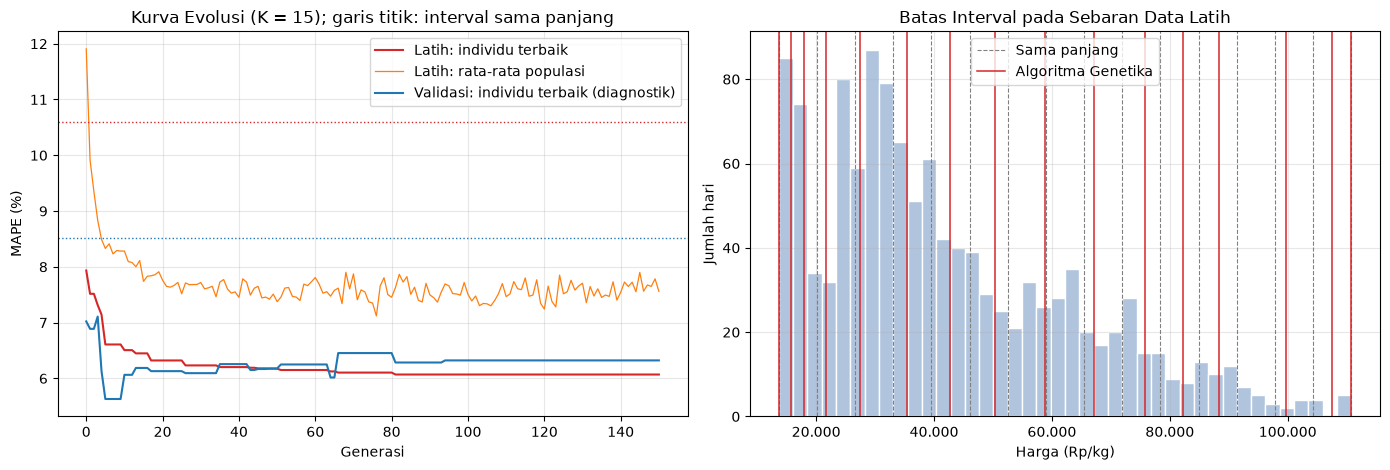

In [3]:
K_CONTOH = 15
UKURAN_POPULASI, JUMLAH_GENERASI = 60, 150
a_lat, y_lat = latih.values[:-1], latih.values[1:]
a_val, y_val = acuan_validasi.values, validasi.values

hasil_ga = jalankan_ga(latih.values, K_CONTOH, validasi.values, acuan_validasi.values,
                       ukuran_populasi=UKURAN_POPULASI, jumlah_generasi=JUMLAH_GENERASI, seed=config.SEED)
acak = pencarian_acak(latih.values, K_CONTOH, UKURAN_POPULASI * JUMLAH_GENERASI, seed=config.SEED)

metode = {
    "Sama panjang": interval_sama_panjang(latih.values, K_CONTOH),
    "Sama frekuensi (kuantil)": batas_kuantil(latih.values, K_CONTOH),
    f"Pencarian acak ({UKURAN_POPULASI * JUMLAH_GENERASI} sampel)": acak["batas"],
    "Algoritma Genetika": hasil_ga["batas"],
}
tabel = pd.DataFrame({
    nama: {
        "MAPE_latih_%": mape_fts(b, latih.values, a_lat, y_lat),
        "MAPE_validasi_%": mape_fts(b, latih.values, a_val, y_val),
        "lebar_interval_min": np.diff(b).min(),
        "lebar_interval_maks": np.diff(b).max(),
    }
    for nama, b in metode.items()
}).T

print("=" * 62)
print(f"satu kali jalan pada K = {K_CONTOH} (seed {config.SEED})")
print("=" * 62)
print(tabel.round(2).to_string())
print()
print(f"Jumlah evaluasi fitness: Algoritma Genetika {UKURAN_POPULASI * (JUMLAH_GENERASI + 1)}, "
      f"pencarian acak {UKURAN_POPULASI * JUMLAH_GENERASI}")

riwayat = hasil_ga["riwayat"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(riwayat.index, riwayat["mape_latih_terbaik"], color="tab:red", label="Latih: individu terbaik")
ax[0].plot(riwayat.index, riwayat["mape_latih_rata2"], color="tab:orange", linewidth=0.9, label="Latih: rata-rata populasi")
ax[0].plot(riwayat.index, riwayat["mape_validasi_terbaik"], color="tab:blue", label="Validasi: individu terbaik (diagnostik)")
ax[0].axhline(tabel.loc["Sama panjang", "MAPE_latih_%"], color="tab:red", linestyle=":", linewidth=1)
ax[0].axhline(tabel.loc["Sama panjang", "MAPE_validasi_%"], color="tab:blue", linestyle=":", linewidth=1)
ax[0].set_title(f"Kurva Evolusi (K = {K_CONTOH}); garis titik: interval sama panjang")
ax[0].set_xlabel("Generasi")
ax[0].set_ylabel("MAPE (%)")
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].hist(latih, bins=40, color="lightsteelblue", edgecolor="white")
for i, b in enumerate(metode["Sama panjang"]):
    ax[1].axvline(b, color="gray", linestyle="--", linewidth=0.8, label="Sama panjang" if i == 0 else None)
for i, b in enumerate(hasil_ga["batas"]):
    ax[1].axvline(b, color="tab:red", linewidth=1.1, label="Algoritma Genetika" if i == 0 else None)
ax[1].set_title("Batas Interval pada Sebaran Data Latih")
ax[1].set_xlabel("Harga (Rp/kg)")
ax[1].set_ylabel("Jumlah hari")
ax[1].xaxis.set_major_formatter(rupiah)
ax[1].grid(alpha=0.3)
ax[1].legend()
plt.tight_layout()
plt.savefig(config.DIR_IMG / "5_satu_kali_jalan_K15.png", dpi=150)
plt.show()

>INTERPRETASI (Satu kali jalan pada K = 15)
>
>Pada satu kali jalan (seed 42), Algoritma Genetika menurunkan MAPE latih dari 10,59% (sama panjang) menjadi 6,07%, dan MAPE validasi dari 8,51% menjadi 6,32%. Namun sebagian besar perbaikan sudah diperoleh hanya dengan membagi interval secara berfrekuensi sama tanpa optimasi apa pun: MAPE validasinya 6,87%, yaitu sekitar tiga perempat dari seluruh perbaikan (1,64 dari 2,19 poin persen). Sumbangan optimasi sendiri sekitar 0,55 poin persen di atas pembagian kuantil. Pencarian acak dengan jumlah evaluasi yang sama menghasilkan MAPE latih 6,93% dan MAPE validasi 7,01%, lebih buruk daripada Algoritma Genetika pada keduanya, tetapi hanya dari satu kali jalan.
>
>Grafik kiri menunjukkan MAPE latih terbaik turun dari sekitar 7,9% menjadi sekitar 6,1% pada generasi ke-80 lalu mendatar. Rata-rata populasi turun cepat dari sekitar 11,9% ke sekitar 7,5% dan bergoyang di sana karena mutasi. Garis diagnostik validasi menarik perhatian: nilainya mencapai titik terendah sekitar 5,6% pada generasi awal (sekitar generasi 5 sampai 10), lalu naik dan berakhir di 6,32% sementara MAPE latih terus membaik. Ini tanda awal overfitting ringan pada data latih. Sesuai rancangan, tidak ada penghentian dini berdasarkan validasi, sehingga angka akhir 6,32% adalah angka yang jujur.
>
>Grafik kanan memperlihatkan batas hasil optimasi menyebar lebih rapat di rentang harga rendah dan menengah tempat sebagian besar data berada, dan lebih jarang di harga tinggi. Interval hasil optimasi berlebar 2.085 sampai 11.363 rupiah, dibanding 6.477 pada pembagian sama panjang. Satu kali jalan belum cukup untuk menyimpulkan keunggulan Algoritma Genetika, karena algoritmanya bersifat acak.

In [4]:
model_ga = FuzzyTimeSeriesChen(hasil_ga["batas"]).fit(latih.values)
pred_ga = pd.Series(model_ga.ramal(acuan_validasi.values), index=validasi.index)
metrik_ga = ringkas_metrik(validasi, pred_ga)

print("=" * 62)
print(f"Aturan FTS hasil GA (K = {K_CONTOH}, data latih)")
print("=" * 62)
print(model_ga.tabel_aturan().round(0).to_string())
print()
print("Metrik pada data validasi (model dari kelas, bukan fungsi cepat):")
for nama, nilai in metrik_ga.items():
    print(f"  {nama:<8}: {nilai:,.2f}")
print()
print(f"Himpunan tanpa aturan : {int((model_ga.jumlah_transisi == 0).sum())}")
print(f"Data per himpunan : minimum {int(model_ga.jumlah_data.min())}, maksimum {int(model_ga.jumlah_data.max())}")

Aturan FTS hasil GA (K = 15, data latih)
          batas_bawah  batas_atas  jumlah_data  jumlah_transisi                 tujuan  titik_ramal
himpunan                                                                                           
A1            13650.0     15735.0           74               74                 A1, A2      15757.0
A2            15735.0     17906.0           71               71             A1, A2, A3      17102.0
A3            17906.0     21678.0           61               61             A2, A3, A4      20378.0
A4            21678.0     27361.0          140              140             A3, A4, A5      25231.0
A5            27361.0     35402.0          248              247             A4, A5, A6      31648.0
A6            35402.0     42686.0          154              154             A5, A6, A7      38982.0
A7            42686.0     50355.0          114              114     A5, A6, A7, A8, A9      46900.0
A8            50355.0     58837.0           92             

>INTERPRETASI (Aturan hasil Algoritma Genetika)
>
>Seluruh 15 himpunan memiliki aturan (tidak ada himpunan tanpa aturan). Jumlah data per himpunan sangat bervariasi, dari 248 pada A5 (Rp 27.361 sampai Rp 35.402) sampai hanya 5 pada A15 dan 9 pada A14. Himpunan tertinggi karenanya memiliki aturan yang dipelajari dari sampel sangat kecil. Pada harga menengah ke atas, himpunan tujuan makin luas: A7 sampai A10 masing-masing dapat berpindah ke lima himpunan (A7 ke A5 sampai A9, A10 ke A8 sampai A12), sedangkan himpunan rendah hanya berpindah ke tetangga langsung. Artinya pada harga tinggi, perpindahan harga dari hari ke hari lebih besar relatif terhadap lebar interval, sehingga aturannya kurang spesifik.
>
>Gejala titik ramal di luar intervalnya sendiri masih ada: titik ramal A1 (Rp 15.757) berada sedikit di atas batas atas A1 (Rp 15.735), dan titik ramal A15 (Rp 106.439) berada di bawah batas bawahnya (Rp 107.589).
>
>Pada data validasi, model ini menghasilkan MAPE 6,32%, RMSE Rp 4.216, dan MAE Rp 2.830. Dibanding Fuzzy Time Series interval sama panjang pada K yang sama (RMSE Rp 5.049 dan MAE Rp 3.583), RMSE dan MAE turun sekitar 16% dan 21%. Dibanding naive (RMSE Rp 3.629 dan MAE Rp 1.908), kesalahannya masih sekitar 16% (RMSE) dan 48% (MAE) lebih besar. MAPE validasi yang dihitung dari kelas sama dengan hasil fungsi cepat, yang menegaskan konsistensi kode.

### ****4. Eksperimen Berulang pada Berbagai Jumlah Interval****

#### ****4.1 Mengapa langkah ini penting?****

Algoritma Genetika bersifat acak, sehingga hasil satu kali jalan dapat kebetulan bagus atau kebetulan buruk. Kesimpulan yang dapat dipertanggungjawabkan hanya diperoleh dari banyak pengulangan dengan seed berbeda, yang dilaporkan sebagai rata-rata dan sebaran. Eksperimen ini sekaligus menjawab pertanyaan utama proyek: apakah optimasi batas interval memperbaiki Fuzzy Time Series pada jumlah interval yang sama.

#### ****4.2 Rancangan eksperimen****

1. Jumlah interval K: 7, 10, 15, dan 20.
2. Untuk setiap K, dua pembagian yang pasti (sama panjang dan sama frekuensi) serta 30 kali jalan untuk pencarian acak dan 30 kali jalan untuk Algoritma Genetika (seed 42 sampai 71). Pencarian acak memakai seed yang berbeda dari Algoritma Genetika agar keduanya saling bebas.
3. Parameter Algoritma Genetika sama dengan bagian 1 dan tidak diubah.
4. Yang dilaporkan: MAPE validasi (rata-rata, simpangan baku, minimum, dan maksimum), persentase seed ketika Algoritma Genetika lebih baik daripada tiap pembanding, dan uji peringkat bertanda Wilcoxon satu sisi.

#### ****4.3 Cara membaca uji statistik****

Uji Wilcoxon membandingkan hasil 30 kali jalan Algoritma Genetika dengan pembanding. Nilai p yang kecil berarti arah selisihnya konsisten di antara seed. Hal ini tidak membuktikan bahwa Algoritma Genetika lebih baik pada data masa depan, karena seluruh perbandingan memakai satu data validasi yang sama. Hasil akhir pada data uji dilaporkan di Notebook 6.

K = 7  selesai (waktu berjalan 52 detik)
K = 10 selesai (waktu berjalan 106 detik)
K = 15 selesai (waktu berjalan 162 detik)
K = 20 selesai (waktu berjalan 221 detik)

MAPE validasi (%) dari 30 saed per K
                             rata2   std  minimum  maksimum
K  metode                                                  
7  Sama panjang              12.15   NaN    12.15     12.15
   Sama frekuensi (kuantil)  10.75   NaN    10.75     10.75
   Pencarian acak             9.61  1.36     7.36     11.74
   Algoritma Genetika         9.86  0.08     9.65     10.04
10 Sama panjang               8.77   NaN     8.77      8.77
   Sama frekuensi (kuantil)   6.27   NaN     6.27      6.27
   Pencarian acak             8.06  0.78     6.65      9.84
   Algoritma Genetika         7.56  1.09     6.45      9.19
15 Sama panjang               8.51   NaN     8.51      8.51
   Sama frekuensi (kuantil)   6.87   NaN     6.87      6.87
   Pencarian acak             6.81  0.46     5.85      7.79
   Algoritma Ge

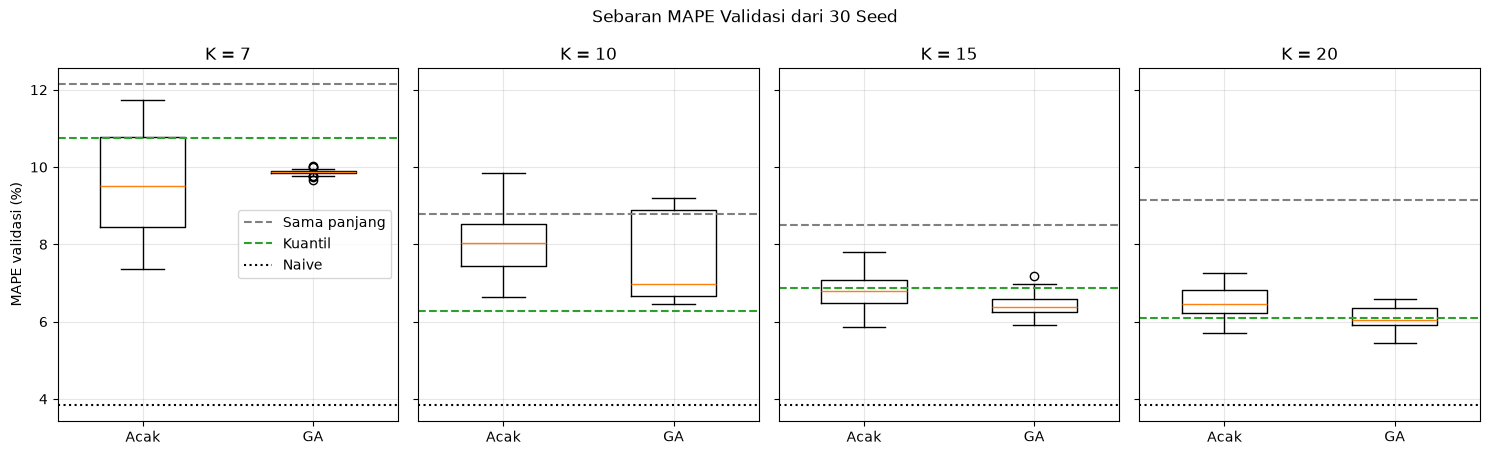

In [5]:
import time
from scipy.stats import wilcoxon

JUMLAH_SEED = 30
DAFTAR_K = [7, 10, 15, 20]
UKURAN_POPULASI, JUMLAH_GENERASI = 60, 150
SEED_AWAL = config.SEED
a_lat, y_lat = latih.values[:-1], latih.values[1:]
a_val, y_val = acuan_validasi.values, validasi.values

baris, batas_ga = [], {}
mulai = time.time()
for K in DAFTAR_K:
    for nama, b in (("Sama panjang", interval_sama_panjang(latih.values, K)),
                    ("Sama frekuensi (kuantil)", batas_kuantil(latih.values, K))):
        baris.append({"K": K, "metode": nama, "seed": -1,
                      "mape_latih": mape_fts(b, latih.values, a_lat, y_lat),
                      "mape_validasi": mape_fts(b, latih.values, a_val, y_val)})
    batas_ga[K] = []
    for i in range(JUMLAH_SEED):
        seed = SEED_AWAL + i
        acak = pencarian_acak(latih.values, K, UKURAN_POPULASI * JUMLAH_GENERASI, seed=seed + 1000)
        ga = jalankan_ga(latih.values, K, ukuran_populasi=UKURAN_POPULASI,
                         jumlah_generasi=JUMLAH_GENERASI, seed=seed)
        batas_ga[K].append(ga["batas"].tolist())
        for nama, hasil in (("Pencarian acak", acak), ("Algoritma Genetika", ga)):
            baris.append({"K": K, "metode": nama, "seed": seed,
                          "mape_latih": hasil["mape_latih"],
                          "mape_validasi": mape_fts(hasil["batas"], latih.values, a_val, y_val)})
    print(f"K = {K:<2} selesai (waktu berjalan {time.time() - mulai:.0f} detik)")

eksperimen = pd.DataFrame(baris)
eksperimen.to_csv(config.DIR_MODEL / "hasil_eksperimen_ga.csv", index=False)
with open(config.DIR_MODEL / "batas_ga_per_seed.json", "w", encoding="utf-8") as f:
    json.dump({str(k): v for k, v in batas_ga.items()}, f)

urutan = ["Sama panjang", "Sama frekuensi (kuantil)", "Pencarian acak", "Algoritma Genetika"]
ringkas = (eksperimen.groupby(["K", "metode"])["mape_validasi"]
           .agg(rata2="mean", std="std", minimum="min", maksimum="max")
           .reindex(pd.MultiIndex.from_product([DAFTAR_K, urutan], names=["K", "metode"])))

print()
print("=" * 62)
print(f"MAPE validasi (%) dari {JUMLAH_SEED} saed per K")
print("=" * 62)
print(ringkas.round(2).to_string())
print("(std kosong: pembagian bersifat pasti, tidak bergantung seed)")

baris_uji = []
for K in DAFTAR_K:
    sub = eksperimen[eksperimen["K"] == K]
    ga_v = sub[sub["metode"] == "Algoritma Genetika"].sort_values("seed")["mape_validasi"].values
    acak_v = sub[sub["metode"] == "Pencarian acak"].sort_values("seed")["mape_validasi"].values
    sp = sub[sub["metode"] == "Sama panjang"]["mape_validasi"].iloc[0]
    kq = sub[sub["metode"] == "Sama frekuensi (kuantil)"]["mape_validasi"].iloc[0]
    baris_uji.append({
        "K": K,
        "GA_lebih_baik_dari_sama_panjang_%": (ga_v < sp).mean() * 100,
        "GA_lebih_baik_dari_kuantil_%": (ga_v < kq).mean() * 100,
        "GA_lebih_baik_dari_acak_%": (ga_v < acak_v).mean() * 100,
        "p_Wilcoxon_GA_vs_kuantil": wilcoxon(ga_v - kq, alternative="less").pvalue,
        "p_Wilcoxon_GA_vs_acak": wilcoxon(ga_v - acak_v, alternative="less").pvalue,
    })
tabel_uji = pd.DataFrame(baris_uji).set_index("K")

print()
print("=" * 62)
print("seberapa sering algoritma genetika lebih baik pada data valdi")
print("=" * 62)
print(tabel_uji.round(4).to_string())
print("p kecil (< 0.05) berarti selisih ke arah GA lebih baik tidak mungkin akibat kebetulan semata,")
print("tetapi hanya menyangkut keacakan algoritma pada data validasi ini, bukan data masa depan.")

fig, ax = plt.subplots(1, len(DAFTAR_K), figsize=(15, 4.6), sharey=True)
naive_val = hasil_baseline.loc["Naive", "MAPE_%"]
for a, K in zip(ax, DAFTAR_K):
    sub = eksperimen[eksperimen["K"] == K]
    data_box = [sub[sub["metode"] == m]["mape_validasi"].values for m in ("Pencarian acak", "Algoritma Genetika")]
    a.boxplot(data_box, tick_labels=["Acak", "GA"], widths=0.5)
    a.axhline(sub[sub["metode"] == "Sama panjang"]["mape_validasi"].iloc[0], color="gray", linestyle="--", label="Sama panjang")
    a.axhline(sub[sub["metode"] == "Sama frekuensi (kuantil)"]["mape_validasi"].iloc[0], color="tab:green", linestyle="--", label="Kuantil")
    a.axhline(naive_val, color="black", linestyle=":", label="Naive")
    a.set_title(f"K = {K}")
    a.grid(alpha=0.3)
ax[0].set_ylabel("MAPE validasi (%)")
ax[0].legend()
fig.suptitle(f"Sebaran MAPE Validasi dari {JUMLAH_SEED} Seed")
plt.tight_layout()
plt.savefig(config.DIR_IMG / "5_eksperimen_berulang.png", dpi=150)
plt.show()

>INTERPRETASI (Eksperimen berulang, 30 seed pada tiap K)
>
>Terhadap interval sama panjang, Algoritma Genetika lebih baik secara rata-rata pada semua K: MAPE validasi 9,86% dibanding 12,15% pada K = 7, 7,56% dibanding 8,77% pada K = 10, 6,42% dibanding 8,51% pada K = 15, dan 6,08% dibanding 9,14% pada K = 20. Pada K = 7, 15, dan 20, seluruh seed lebih baik daripada interval sama panjang, sedangkan pada K = 10 hanya 67% seed (20 dari 30).
>
>Terhadap pembagian berfrekuensi sama (kuantil), hasilnya campuran. Pada K = 7 Algoritma Genetika unggul pada semua seed (9,86% dibanding 10,75%). Pada K = 15 unggul pada 93% seed (6,42% dibanding 6,87%, p mendekati nol). Pada K = 20 hasilnya imbang (6,08% dibanding 6,09%, unggul pada 57% seed, p = 0,53). Pada K = 10 Algoritma Genetika kalah: kuantil menghasilkan 6,27% sedangkan hasil Algoritma Genetika terbaik hanya 6,45% dan rata-ratanya 7,56%, sehingga tidak ada satu seed pun yang mengalahkan kuantil. Dengan demikian, manfaat optimasi evolusioner dibanding pembagian berfrekuensi sama tidak konsisten pada data validasi ini.
>
>Terhadap pencarian acak dengan jumlah evaluasi yang sama, Algoritma Genetika lebih baik pada K = 10 (unggul pada 63% seed, p = 0,044), K = 15 (73%, p = 0,0006), dan K = 20 (83%, p = 0,0001). Pada K = 7 tidak: Algoritma Genetika unggul pada 47% seed (p = 0,85) dan rata-ratanya 9,86% lebih tinggi daripada pencarian acak (9,61%).
>
>Sebaran hasil juga berbeda antar K. Pada K = 7 Algoritma Genetika menghasilkan nilai yang nyaris sama pada semua seed (simpangan baku 0,08), jauh lebih konsisten daripada pencarian acak (simpangan baku 1,36, rentang 7,36% sampai 11,74%). Artinya Algoritma Genetika menemukan pembagian yang praktis sama pada setiap jalan, dan pembagian itu bukan yang terbaik pada data validasi, sedangkan beberapa pembagian acak kebetulan jauh lebih baik. Pada K = 10 sebaran Algoritma Genetika justru lebar (simpangan baku 1,09, rentang 6,45% sampai 9,19%), dan grafik menunjukkan median sekitar 7,0% berada di bawah rata-rata, tanda sebagian seed berhenti pada pembagian yang jauh lebih buruk daripada yang lain.
>
>Garis naive (3,85%) berada jauh di bawah seluruh metode pada semua K.

### ****5. Diagnosis Hasil dan Perbandingan dengan Model Dasar****

#### ****5.1 Mengapa langkah ini penting?****

Bagian 4 menunjukkan hasil campuran: Algoritma Genetika lebih baik daripada interval sama panjang, tetapi dibanding pembagian berfrekuensi sama hasilnya tidak konsisten. Sebelum menyimpulkan, perlu diketahui penyebabnya. Ada dua kemungkinan yang berbeda: Algoritma Genetika gagal mengoptimasi data latih, atau Algoritma Genetika berhasil mengoptimasi data latih tetapi hasilnya tidak berlaku pada data validasi. Jawabannya menentukan bagaimana hasil proyek dilaporkan.

#### ****5.2 Yang dilakukan****

Dua sel berikut:
1. Membandingkan MAPE latih dan MAPE validasi tiap metode, menghitung seberapa sering Algoritma Genetika lebih baik pada data latih, dan menghitung korelasi antara MAPE latih dan MAPE validasi di antara 30 seed. Grafik titik menampilkan MAPE latih dan validasi tiap seed.
2. Menghitung perbaikan Algoritma Genetika terhadap interval sama panjang pada K yang sama, menetapkan K terpilih (rata-rata MAPE validasi Algoritma Genetika terkecil), mencatat seed terbaik menurut MAPE latih, membandingkan seluruh hasil dengan model dasar, dan menyimpan konfigurasi di folder Model. Seed terbaik dipilih menurut MAPE latih dan bukan validasi agar pemilihan model tidak memakai data validasi yang sama dengan yang dilaporkan.

Rata-rata MAPE latih dan valdi (%)
                             mape_latih  mape_validasi  selisih_validasi_latih
K  metode                                                                     
7  Sama panjang                   20.85          12.15                   -8.70
   Sama frekuensi (kuantil)       14.48          10.75                   -3.73
   Pencarian acak                 10.98           9.61                   -1.36
   Algoritma Genetika              9.35           9.86                    0.51
10 Sama panjang                   14.16           8.77                   -5.39
   Sama frekuensi (kuantil)        9.72           6.27                   -3.45
   Pencarian acak                  8.72           8.06                   -0.66
   Algoritma Genetika              7.67           7.56                   -0.11
15 Sama panjang                   10.59           8.51                   -2.08
   Sama frekuensi (kuantil)        8.05           6.87                   -1.18
   Pencarian acak

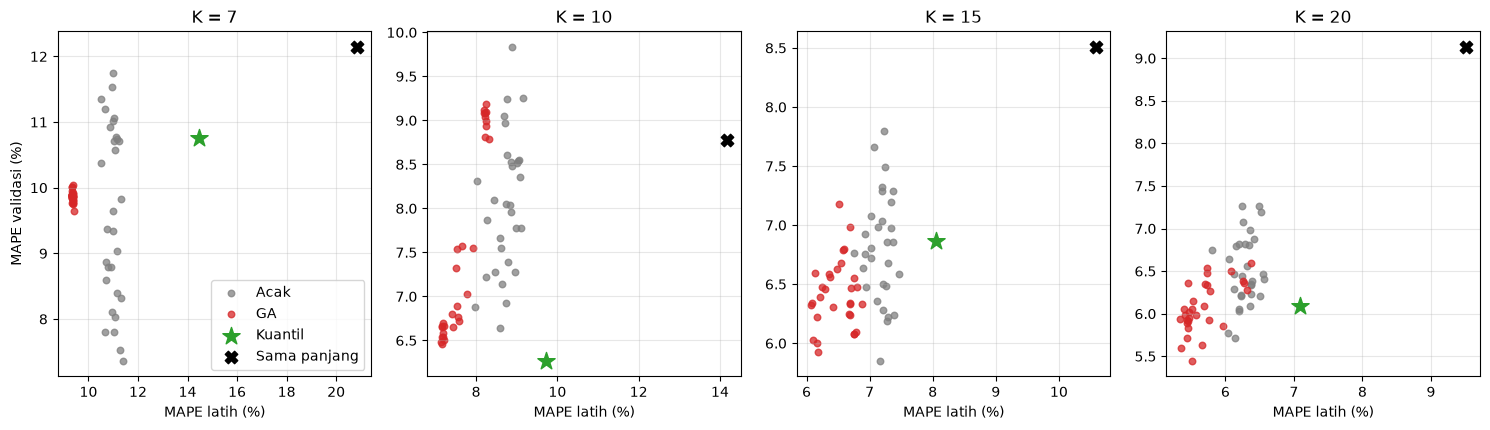

In [6]:
from scipy.stats import spearmanr

ringkas_lv = (eksperimen.groupby(["K", "metode"])[["mape_latih", "mape_validasi"]].mean()
              .reindex(pd.MultiIndex.from_product([DAFTAR_K, urutan], names=["K", "metode"])))
ringkas_lv["selisih_validasi_latih"] = ringkas_lv["mape_validasi"] - ringkas_lv["mape_latih"]

print("=" * 62)
print("Rata-rata MAPE latih dan valdi (%)")
print("=" * 62)
print(ringkas_lv.round(2).to_string())

baris = []
for K in DAFTAR_K:
    sub = eksperimen[eksperimen["K"] == K]
    ga = sub[sub["metode"] == "Algoritma Genetika"].sort_values("seed")
    ac = sub[sub["metode"] == "Pencarian acak"].sort_values("seed")
    kq = sub[sub["metode"] == "Sama frekuensi (kuantil)"].iloc[0]
    baris.append({
        "K": K,
        "GA_latih_lebih_baik_dari_acak_%": (ga["mape_latih"].values < ac["mape_latih"].values).mean() * 100,
        "GA_latih_lebih_baik_dari_kuantil_%": (ga["mape_latih"].values < kq["mape_latih"]).mean() * 100,
        "korelasi_latih_validasi_GA": spearmanr(ga["mape_latih"], ga["mape_validasi"]).statistic,
        "korelasi_latih_validasi_acak": spearmanr(ac["mape_latih"], ac["mape_validasi"]).statistic,
    })

print()
print("=" * 62)
print("kemampuan mengoptimasi data latih dan keterkaitannya dengan validasi")
print("=" * 62)
print(pd.DataFrame(baris).set_index("K").round(2).to_string())
print("Korelasi (Spearman) antar 30 seed: positif berarti seed yang lebih baik pada data latih")
print("juga cenderung lebih baik pada data validasi; mendekati nol atau negatif berarti tidak.")

fig, ax = plt.subplots(1, len(DAFTAR_K), figsize=(15, 4.4))
for a, K in zip(ax, DAFTAR_K):
    sub = eksperimen[eksperimen["K"] == K]
    for metode, warna, label in (("Pencarian acak", "gray", "Acak"), ("Algoritma Genetika", "tab:red", "GA")):
        s = sub[sub["metode"] == metode]
        a.scatter(s["mape_latih"], s["mape_validasi"], s=22, color=warna, alpha=0.75, label=label)
    kq = sub[sub["metode"] == "Sama frekuensi (kuantil)"].iloc[0]
    sp = sub[sub["metode"] == "Sama panjang"].iloc[0]
    a.scatter(kq["mape_latih"], kq["mape_validasi"], marker="*", s=170, color="tab:green", label="Kuantil", zorder=3)
    a.scatter(sp["mape_latih"], sp["mape_validasi"], marker="X", s=80, color="black", label="Sama panjang", zorder=3)
    a.set_title(f"K = {K}")
    a.set_xlabel("MAPE latih (%)")
    a.grid(alpha=0.3)
ax[0].set_ylabel("MAPE validasi (%)")
ax[0].legend()
plt.tight_layout()
plt.savefig(config.DIR_IMG / "5_latih_vs_validasi.png", dpi=150)
plt.show()

>INTERPRETASI (Diagnosis: MAPE latih dan validasi)
>
>Algoritma Genetika berhasil mengoptimasi data latih. MAPE latihnya lebih kecil daripada pembagian kuantil pada 100% seed di semua K, dan lebih kecil daripada pencarian acak pada 90% sampai 100% seed (100% pada K = 7, 96,7% pada K = 10, 100% pada K = 15, dan 90% pada K = 20). Rata-rata MAPE latih Algoritma Genetika juga terendah di tiap K (9,35%, 7,67%, 6,48%, dan 5,68%). Jadi kekurangan Algoritma Genetika pada validasi bukan akibat optimasi yang gagal.
>
>Keunggulan pada data latih tidak sepenuhnya berpindah ke data validasi. Dibanding kuantil, Algoritma Genetika unggul pada data latih sebesar 5,13, 2,05, 1,57, dan 1,41 poin persen (K = 7, 10, 15, dan 20). Pada data validasi keunggulan itu menyusut menjadi 0,89 poin (K = 7) dan 0,45 poin (K = 15), praktis hilang pada K = 20 (0,01 poin), dan berbalik menjadi kekalahan 1,29 poin pada K = 10. Pembagian kuantil justru lebih baik pada validasi daripada pada data latih (selisih -3,73, -3,45, -1,18, dan -1,01 poin), sedangkan Algoritma Genetika hampir tidak membaik dan bahkan memburuk pada K = 7 (+0,51) dan K = 20 (+0,40).
>
>Hampir semua metode memiliki MAPE validasi lebih rendah daripada MAPE latih. Artinya periode validasi lebih mudah ditebak daripada periode latih yang memuat tahun 2020 sampai 2022 dengan fluktuasi besar (koefisien variasi sekitar 58% pada 2020 dan 2021 menurut Notebook 1). Dugaan kami, Algoritma Genetika menyesuaikan batas interval dengan karakter periode latih, sedangkan pembagian kuantil hanya bergantung pada sebaran harga sehingga lebih tahan terhadap perubahan karakter data. Dugaan ini belum diuji langsung.
>
>Korelasi antara MAPE latih dan MAPE validasi di antara 30 seed bervariasi menurut K: 0,89 pada K = 10 dan 0,62 pada K = 20, yang berarti seed dengan MAPE latih lebih baik cenderung lebih baik pula pada validasi. Pada grafik K = 10, hasil Algoritma Genetika terpisah menjadi dua kelompok: satu di sekitar MAPE latih 7,2% (MAPE validasi sekitar 6,5% sampai 7,5%) dan satu di sekitar 8,2% (MAPE validasi sekitar 8,8% sampai 9,2%). Kelompok kedua tampak berhenti pada pembagian yang lebih buruk, dan ini menjelaskan sebaran yang lebar pada K = 10. Pada K = 15 korelasinya hanya 0,09, sehingga selisih antar seed pada data latih tidak memprediksi hasil validasi.
>
>Pada K = 7 semua seed Algoritma Genetika menghasilkan MAPE latih yang hampir identik (sekitar 9,35%), sehingga korelasi -0,29 hanya mencerminkan selisih sangat kecil. Beberapa pembagian acak yang kebetulan baik pada validasi (sekitar 7,4% sampai 8%) memiliki MAPE latih lebih buruk (sekitar 11%). Artinya pada K = 7, pembagian yang optimal pada data latih bukan pembagian yang optimal pada data validasi.

perbaikan GA terhadap interval sama panjang pada K yang sama (validasi)
    sama_panjang_%  GA_rata2_%  perbaikan_relatif_%
K                                                  
7            12.15        9.86                18.79
10            8.77        7.56                13.84
15            8.51        6.42                24.59
20            9.14        6.08                33.45

K dengan rata-rata MAPE validasi GA terkecil: K = 20
Seed terbaik menurut MAPE LATIH (bukan validasi) pada tiap K, dan MAPE validasinya:
  K = 7  seed 49: MAPE latih 9.33%, MAPE validasi 9.88%
  K = 10 seed 63: MAPE latih 7.15%, MAPE validasi 6.48%
  K = 15 seed 42: MAPE latih 6.07%, MAPE validasi 6.32%
  K = 20 seed 50: MAPE latih 5.34%, MAPE validasi 5.94%

Posisi GA-FTS terhadap seluruh model dasar pada data validasi
                                               MAPE_%  MAPE_terhadap_naive_(kali)
model                                                                            
ARIMA(3, 1, 2)             

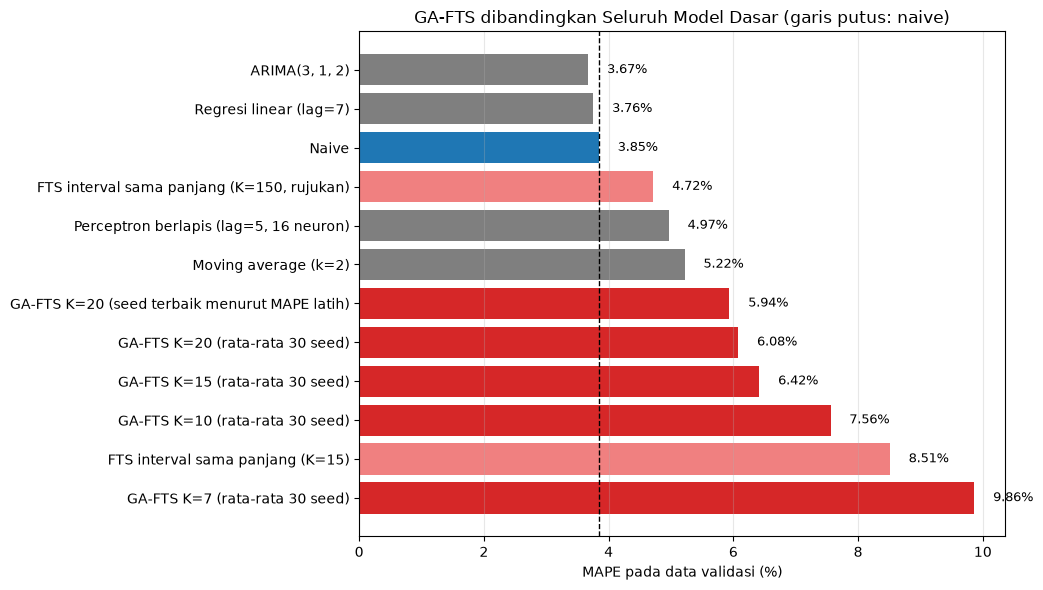


Tersimpan: hasil_ga_vs_baseline_validasi.csv dan konfigurasi_ga.json di folder Model


In [7]:
PARAM_GA = {    # sesuai nilai bawaan jalankan_ga dan rancangan bagian 1
    "ukuran_populasi": UKURAN_POPULASI, "jumlah_generasi": JUMLAH_GENERASI,
    "peluang_crossover": 0.9, "peluang_mutasi": 0.2, "sigma_mutasi": 0.25,
    "ukuran_turnamen": 3, "elitisme": 2, "faktor_lebar_min": 0.25,
}

ga_semua = eksperimen[eksperimen["metode"] == "Algoritma Genetika"]
sama_panjang = eksperimen[eksperimen["metode"] == "Sama panjang"].set_index("K")["mape_validasi"]
rata_ga = ga_semua.groupby("K")["mape_validasi"].mean()

tabel_perbaikan = pd.DataFrame({
    "sama_panjang_%": sama_panjang,
    "GA_rata2_%": rata_ga,
    "perbaikan_relatif_%": (1 - rata_ga / sama_panjang) * 100,
})
print("=" * 62)
print("perbaikan GA terhadap interval sama panjang pada K yang sama (validasi)")
print("=" * 62)
print(tabel_perbaikan.round(2).to_string())

K_terpilih = int(rata_ga.idxmin())
terbaik_latih = {}
for K in DAFTAR_K:
    s = ga_semua[ga_semua["K"] == K]
    baris_terbaik = s.loc[s["mape_latih"].idxmin()]
    terbaik_latih[K] = baris_terbaik

print()
print(f"K dengan rata-rata MAPE validasi GA terkecil: K = {K_terpilih}")
print("Seed terbaik menurut MAPE LATIH (bukan validasi) pada tiap K, dan MAPE validasinya:")
for K, b in terbaik_latih.items():
    print(f"  K = {K:<2} seed {int(b['seed'])}: MAPE latih {b['mape_latih']:.2f}%, MAPE validasi {b['mape_validasi']:.2f}%")

baris = []
for K in DAFTAR_K:
    baris.append({"model": f"GA-FTS K={K} (rata-rata {JUMLAH_SEED} seed)", "MAPE_%": rata_ga[K], "jenis": "GA"})
baris.append({"model": f"GA-FTS K={K_terpilih} (seed terbaik menurut MAPE latih)",
              "MAPE_%": terbaik_latih[K_terpilih]["mape_validasi"], "jenis": "GA"})
for nama, nilai in hasil_baseline["MAPE_%"].items():
    baris.append({"model": nama, "MAPE_%": nilai, "jenis": "FTS" if nama.startswith("FTS") else "lain"})
gabungan = pd.DataFrame(baris).set_index("model").sort_values("MAPE_%")
gabungan["MAPE_terhadap_naive_(kali)"] = gabungan["MAPE_%"] / hasil_baseline.loc["Naive", "MAPE_%"]

print()
print("=" * 62)
print("Posisi GA-FTS terhadap seluruh model dasar pada data validasi")
print("=" * 62)
print(gabungan[["MAPE_%", "MAPE_terhadap_naive_(kali)"]].round(2).to_string())

fig, ax = plt.subplots(figsize=(10.5, 6))
urut = gabungan["MAPE_%"].sort_values(ascending=False)
peta_warna = {"GA": "tab:red", "FTS": "lightcoral", "lain": "tab:gray"}
warna = [("tab:blue" if n == "Naive" else peta_warna[gabungan.loc[n, "jenis"]]) for n in urut.index]
ax.barh(urut.index, urut.values, color=warna)
ax.axvline(hasil_baseline.loc["Naive", "MAPE_%"], color="black", linestyle="--", linewidth=1)
for i, nilai in enumerate(urut.values):
    ax.text(nilai + 0.3, i, f"{nilai:.2f}%", va="center", fontsize=9)
ax.set_xlabel("MAPE pada data validasi (%)")
ax.set_title("GA-FTS dibandingkan Seluruh Model Dasar (garis putus: naive)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(config.DIR_IMG / "5_ga_vs_model_dasar.png", dpi=150)
plt.show()

gabungan.to_csv(config.DIR_MODEL / "hasil_ga_vs_baseline_validasi.csv")
konfigurasi_ga = {
    "parameter": PARAM_GA,
    "daftar_K": DAFTAR_K,
    "jumlah_seed": JUMLAH_SEED,
    "seed_awal": SEED_AWAL,
    "K_terpilih_menurut_validasi": K_terpilih,
    "seed_terbaik_menurut_mape_latih": {str(K): int(b["seed"]) for K, b in terbaik_latih.items()},
    "batas_seed_terbaik": {str(K): batas_ga[K][int(b["seed"]) - SEED_AWAL] for K, b in terbaik_latih.items()},
}
with open(config.DIR_MODEL / "konfigurasi_ga.json", "w", encoding="utf-8") as f:
    json.dump(konfigurasi_ga, f, indent=2, ensure_ascii=False)
print()
print("Tersimpan: hasil_ga_vs_baseline_validasi.csv dan konfigurasi_ga.json di folder Model")

>INTERPRETASI (Posisi GA-FTS terhadap model dasar)
>
>Terhadap interval sama panjang pada K yang sama, Algoritma Genetika memperbaiki MAPE validasi rata-rata sebesar 18,8% (K = 7), 13,8% (K = 10), 24,6% (K = 15), dan 33,5% (K = 20). K dengan rata-rata MAPE validasi terkecil adalah K = 20 (6,08%), sehingga K = 20 menjadi K terpilih.
>
>Seed terbaik menurut MAPE latih dicatat tanpa melihat data validasi: seed 49 pada K = 7 (MAPE latih 9,33%, validasi 9,88%), seed 63 pada K = 10 (7,15% dan 6,48%), seed 42 pada K = 15 (6,07% dan 6,32%), dan seed 50 pada K = 20 (5,34% dan 5,94%). Hasil validasinya lebih baik atau sama dengan rata-rata 30 seed pada K = 10 (6,48% dibanding 7,56%), K = 15 (6,32% dibanding 6,42%), dan K = 20 (5,94% dibanding 6,08%), dan hampir sama pada K = 7 (9,88% dibanding 9,86%). Hasil ini mendukung prosedur menjalankan algoritma beberapa kali lalu mengambil yang terbaik menurut data latih sebagai cara memilih model akhir.
>
>Posisi terhadap model dasar: Fuzzy Time Series hasil optimasi terbaik (K = 20, seed terbaik 5,94% dan rata-rata 6,08%) masih sekitar 1,5 sampai 1,6 kali MAPE naive, dan masih lebih buruk daripada moving average (5,22%), perceptron berlapis (4,97%), dan Fuzzy Time Series K = 150 (4,72%). Dibanding Fuzzy Time Series interval sama panjang terbaik pada rentang rancangan (K = 15, 8,51%), hasil K = 20 menurunkan MAPE sekitar 29% dan menutup sekitar 64% selisih menuju rujukan K = 150. ARIMA, regresi linear, dan naive tetap yang terbaik pada data validasi.
>
>Pada K = 7, Algoritma Genetika (9,86%) bahkan lebih buruk daripada interval sama panjang pada K = 15 (8,51%). Pada jumlah himpunan sekecil itu, kekasaran interval membatasi akurasi lebih kuat daripada manfaat optimasi batas.

### ****6. Ringkasan dan Langkah Berikutnya****

#### ****6.1 Ringkasan****

1. Modul Algoritma Genetika ditulis dan diuji. Fungsi evaluasi cepat menghasilkan MAPE yang identik dengan kelas Fuzzy Time Series, dan setiap kromosom menghasilkan pembagian semesta yang sah.
2. Rancangan dan parameter ditetapkan sebelum eksperimen dan tidak disetel mengikuti hasil validasi.
3. Algoritma Genetika berhasil mengoptimasi data latih: MAPE latihnya lebih baik daripada pembagian kuantil pada seluruh seed di semua K.
4. Pada data validasi, Algoritma Genetika lebih baik daripada interval sama panjang pada K yang sama dengan perbaikan rata-rata 13,8% sampai 33,5%.
5. Terhadap pencarian acak dengan anggaran evaluasi yang sama, Algoritma Genetika lebih baik pada K = 10, 15, dan 20 (p di bawah 0,05), tetapi tidak pada K = 7.
6. Terhadap pembagian kuantil, hasilnya campuran: unggul pada K = 7 dan 15, imbang pada K = 20, dan kalah pada K = 10. Keunggulan pada data latih tidak sepenuhnya berpindah ke data validasi.
7. K terpilih menurut validasi adalah 20 dengan MAPE validasi rata-rata 6,08% (5,94% untuk seed terbaik menurut MAPE latih), yang masih sekitar 1,5 sampai 1,6 kali MAPE naive.

#### ****6.2 Klaim yang dapat dipertanggungjawabkan****

Berdasarkan data validasi, klaim proyek dirumuskan sebagai berikut. Optimasi batas interval dengan Algoritma Genetika secara konsisten memperbaiki Fuzzy Time Series dibanding pembagian sama panjang pada jumlah interval yang sama, dan lebih baik daripada pencarian acak pada tiga dari empat jumlah interval. Namun keunggulannya atas pembagian berfrekuensi sama tidak konsisten (unggul pada dua dari empat K, imbang pada satu, dan kalah pada satu), dan seluruh Fuzzy Time Series pada K sampai 20 masih lebih buruk daripada model naive. Klaim ini masih bersifat sementara sampai diuji pada data uji.

#### ****6.3 Keterbatasan****

1. Seluruh perbandingan memakai satu periode validasi (7 November 2024 sampai 6 November 2025), sehingga hasilnya dapat berbeda pada periode lain.
2. Fitness hanya memakai MAPE pada data latih, tanpa mekanisme yang melindungi hasil dari perubahan karakter data.
3. Parameter Algoritma Genetika sengaja tidak disetel. Pada K = 10 sebagian seed tampak berhenti pada pembagian yang lebih buruk, yang diduga akibat konvergensi dini, tetapi hal ini tidak diselidiki lebih jauh.
4. Fuzzy Time Series yang dipakai adalah model Chen asli orde satu tanpa pembobotan frekuensi, sehingga titik ramalnya sering berada di tepi interval.
5. Pembagian kuantil yang jauh lebih sederhana menghasilkan MAPE validasi yang hampir sama baiknya pada sebagian K.

#### ****6.4 Langkah berikutnya****

Pada Notebook 6 (evaluasi akhir), data uji dibuka untuk pertama dan satu-satunya kali, dengan konfigurasi yang sudah terkunci:
1. Seluruh model dilatih ulang pada gabungan data latih dan validasi, termasuk Algoritma Genetika yang dijalankan ulang dengan parameter yang sama dan seed dipilih menurut MAPE pada data pelatihan.
2. Seluruh model diukur pada data uji dengan MAPE, RMSE, dan MAE.
3. Galat dirinci menurut hari dalam minggu dan pada hari ketika harga berubah saja, untuk memeriksa pengaruh hari Senin dan pengulangan harga pada hari libur.
4. Selisih antar model diuji secara statistik (uji Diebold-Mariano).